In [2]:
import numpy as np 
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.svm import SVR
import time
import seaborn as sns
from joblib import Parallel, delayed

Task 1

Perform data pre-processing activities. This may include data preparation, data cleaning,
normalization, standardization, and feature analysis.

['Unnamed: 0', 'Bus Voltage-1', 'Bus Voltage-2', 'Bus Voltage-3', 'Bus Voltage-4', 'Bus Voltage-5', 'Bus Voltage-6', 'Bus Voltage-7', 'Bus Voltage-8', 'Bus Voltage-9', 'Bus Angles-1', 'Bus Angles-2', 'Bus Angles-3', 'Bus Angles-4', 'Bus Angles-5', 'Bus Angles-6', 'Bus Angles-7', 'Bus Angles-8', 'Bus Angles-9', ' P generation-1', ' P generation-2', ' P generation-3', ' P generation-4', ' P generation-5', ' P generation-6', ' P generation-7', ' P generation-8', ' P generation-9', 'Q generation-1', 'Q generation-2', 'Q generation-3', 'Q generation-4', 'Q generation-5', 'Q generation-6', 'Q generation-7', 'Q generation-8', 'Q generation-9', 'P demand-1', 'P demand-2', 'P demand-3', 'P demand-4', 'P demand-5', 'P demand-6', 'P demand-7', 'P demand-8', 'P demand-9', 'Q demand-1', 'Q demand-2', 'Q demand-3', 'Q demand-4', 'Q demand-5', 'Q demand-6', 'Q demand-7', 'Q demand-8', 'Q demand-9', 'Pflow Bus 1-1', 'Pflow Bus 1-2', 'Pflow Bus 1-3', 'Pflow Bus 1-4', 'Pflow Bus 1-5', 'Pflow Bus 1-6', '

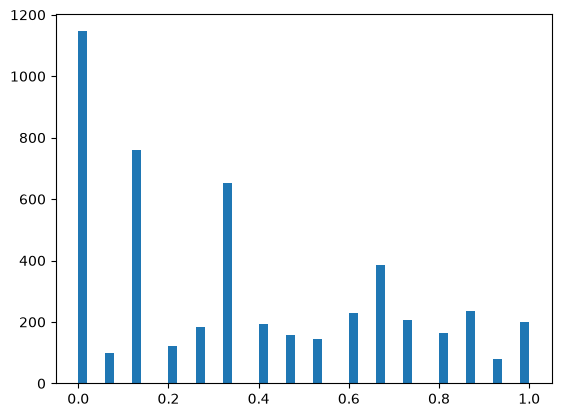

<Figure size 640x480 with 0 Axes>

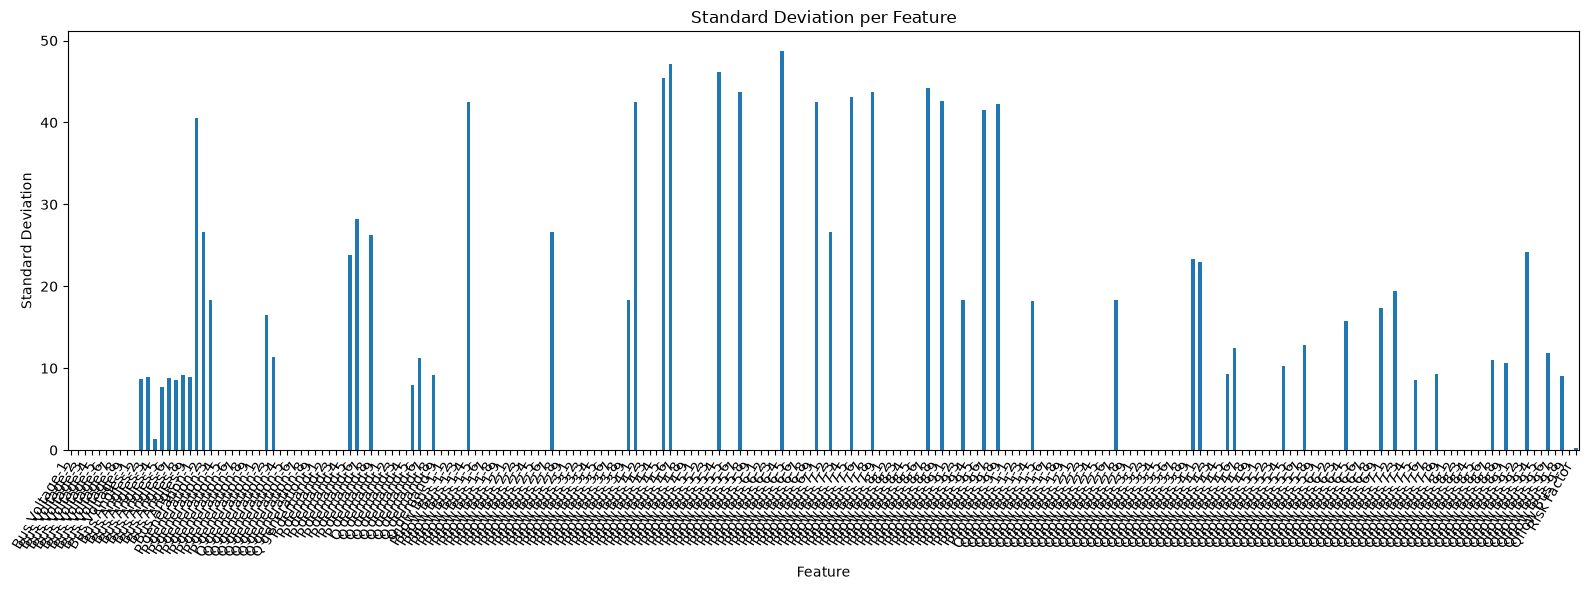

['Bus Voltage-1', 'Bus Angles-1', ' P generation-4', ' P generation-5', ' P generation-6', ' P generation-7', ' P generation-8', ' P generation-9', 'Q generation-1', 'Q generation-4', 'Q generation-5', 'Q generation-6', 'Q generation-7', 'Q generation-8', 'Q generation-9', 'P demand-1', 'P demand-2', 'P demand-3', 'P demand-4', 'P demand-7', 'P demand-9', 'Q demand-1', 'Q demand-2', 'Q demand-3', 'Q demand-4', 'Q demand-7', 'Q demand-9', 'Pflow Bus 1-1', 'Pflow Bus 1-2', 'Pflow Bus 1-3', 'Pflow Bus 1-5', 'Pflow Bus 1-6', 'Pflow Bus 1-7', 'Pflow Bus 1-8', 'Pflow Bus 1-9', 'Pflow Bus 2-1', 'Pflow Bus 2-2', 'Pflow Bus 2-3', 'Pflow Bus 2-4', 'Pflow Bus 2-5', 'Pflow Bus 2-6', 'Pflow Bus 2-8', 'Pflow Bus 2-9', 'Pflow Bus 3-1', 'Pflow Bus 3-2', 'Pflow Bus 3-3', 'Pflow Bus 3-4', 'Pflow Bus 3-5', 'Pflow Bus 3-6', 'Pflow Bus 3-7', 'Pflow Bus 3-8', 'Pflow Bus 4-2', 'Pflow Bus 4-3', 'Pflow Bus 4-4', 'Pflow Bus 4-7', 'Pflow Bus 4-8', 'Pflow Bus 4-9', 'Pflow Bus 5-1', 'Pflow Bus 5-2', 'Pflow Bus 5-3

In [31]:
Input = pd.read_csv("data/Project_Data_EE4C12_EPE_PS.csv", delimiter=',')

print(list(Input))

plt.figure()
hist_risk = plt.hist(Input['Risk Factor'], bins = 50)
plt.figure()
#plt.plot(Input['Risk Factor'][0:100])

#Standard deviations of the features
stds = Input.iloc[:, 1:].select_dtypes(include="number").std()

# Plot
plt.figure(figsize=(16, 6))
stds.plot(kind="bar")

plt.title("Standard Deviation per Feature")
plt.xlabel("Feature")
plt.ylabel("Standard Deviation")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

zero_std_columns = stds[stds == 0].index.tolist()

print(zero_std_columns)


#removing the features with zero std. deviation
Input_clean = Input.drop(columns=zero_std_columns)

print("Number of features before cleaning Features without variation: ", len(Input.columns))
print("number of features after  cleaning Features without variation: ", len(Input_clean.columns))

Many of the featurs had zero standard deviation. A new dataframe containing only the columns with standard deviation was created (called Input.cleaned) was created, that only contains columns with Information. 

The fact that the standard deviation is zero, is because they represent sizes in the network that do not exist, or that are constant by definition. For example Bus Voltage and Angle 1 are constant, because this is the reference of the network and therefore constant.  The Power and reactive Power generation are constant at all Busses exept for Bus 1 to 3 because only bus 1 to 3 have Generators. The same is the case for the demand at all busses exept for bus 5,6 and 8, because they are the only ones with demand. The flow has no variation at many combinations, because not all busses have a direct connection (for example Bus 7 to Bus 4). 

Add a correlation matrix

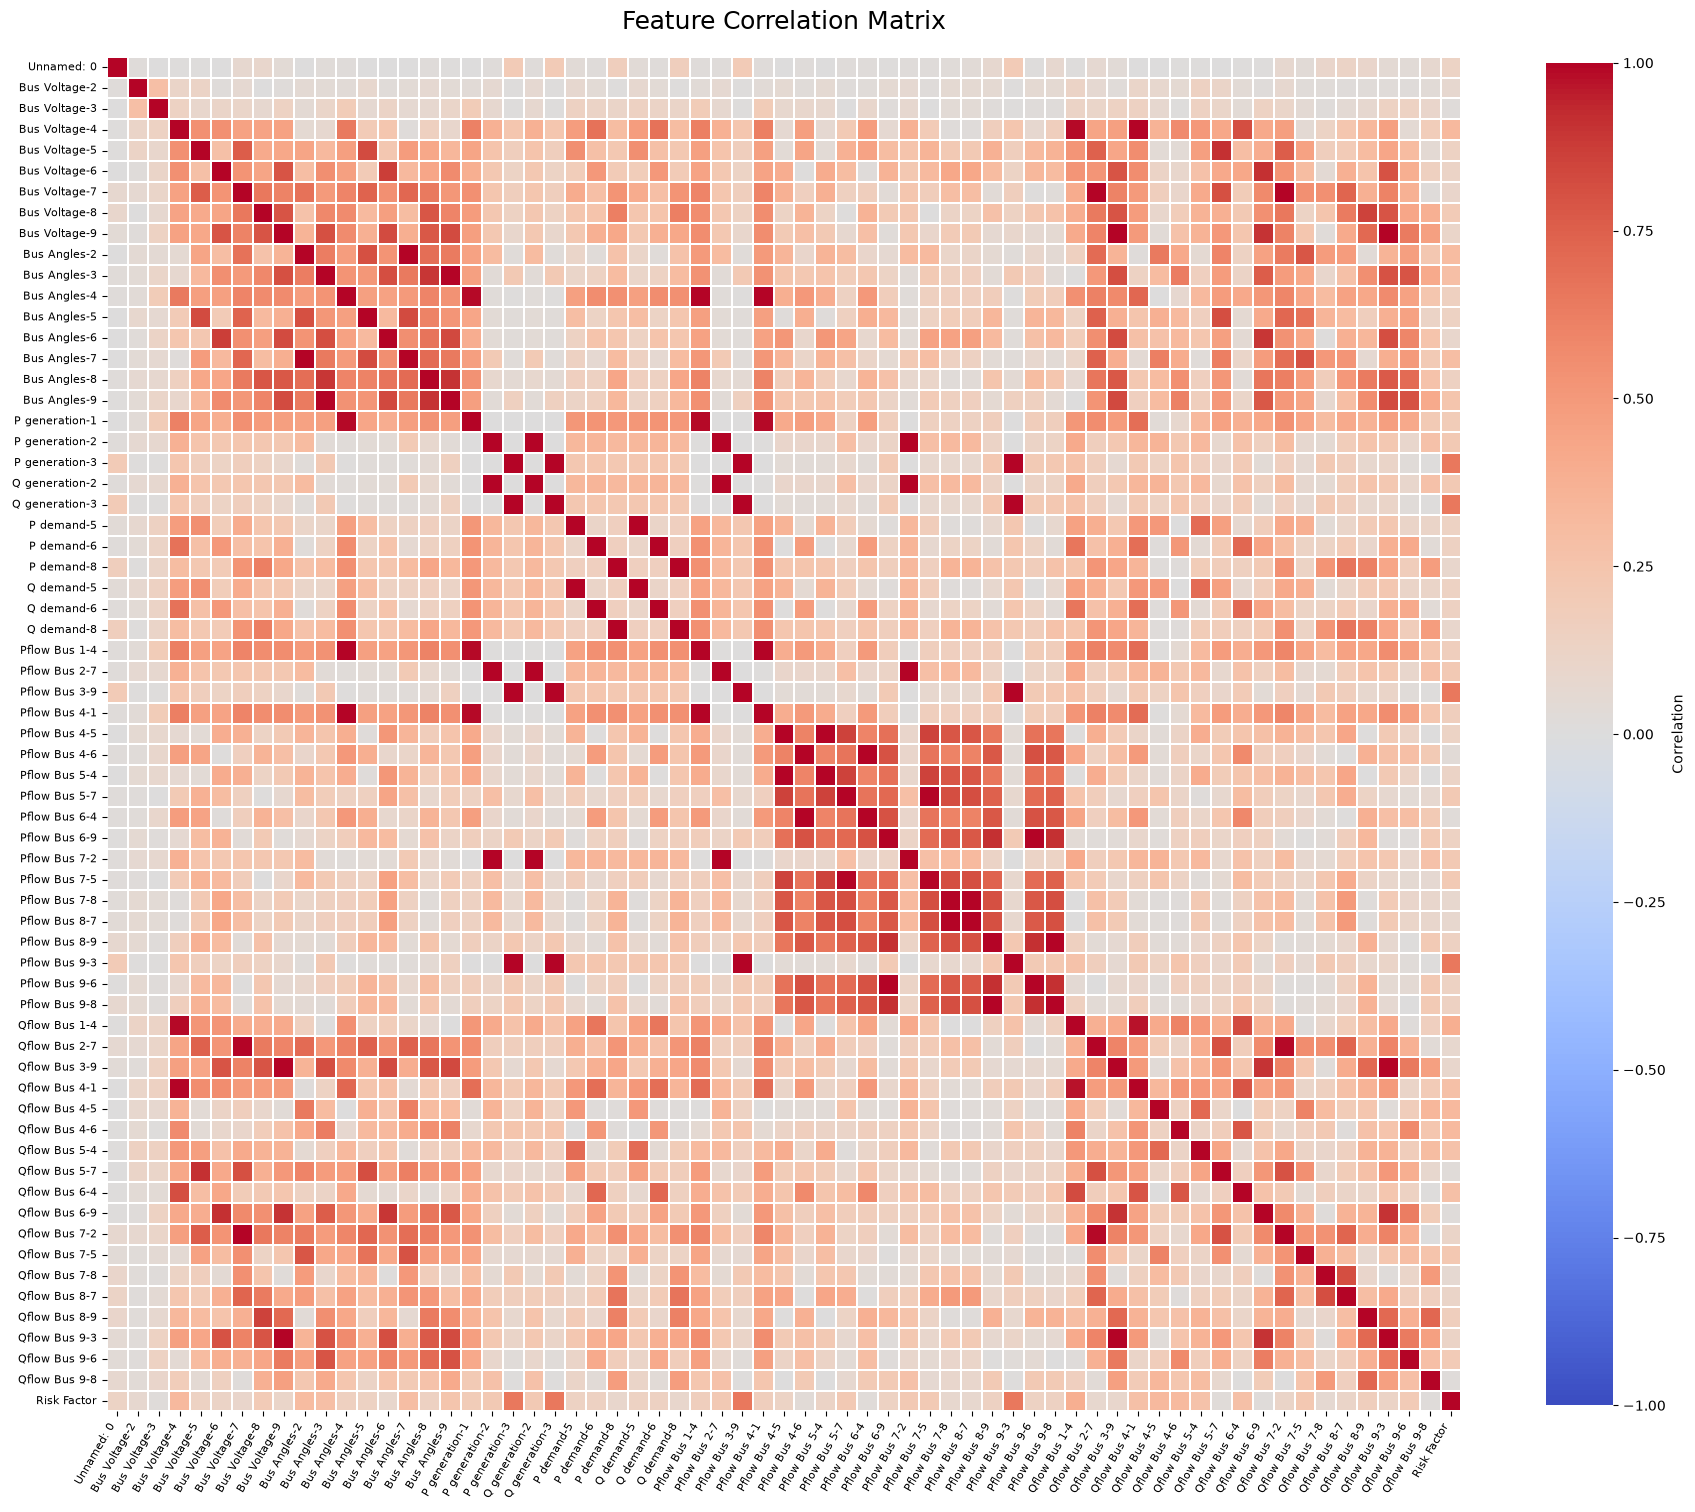

In [4]:
def plot_correlation_matrix(df):
    # Keep numeric columns only
    numeric_df = df.select_dtypes(include="number")

    # Compute full correlation matrix
    corr = numeric_df.corr()

    # Scale figure size based on number of features
    n_features = len(corr.columns)
    fig_size = max(14, n_features * 0.28)

    plt.figure(figsize=(fig_size, fig_size))

    sns.heatmap(
        corr.abs(),
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,

        # Important for a large matrix:
        annot=False,          # Don't print a number in every cell
        square=True,
        linewidths=0.15,

        cbar_kws={
            "label": "Correlation",
            "shrink": 0.75
        }
    )

    plt.title(
        "Feature Correlation Matrix",
        fontsize=18,
        pad=20
    )

    plt.xticks(
        rotation=60,
        ha="right",
        fontsize=8
    )

    plt.yticks(
        rotation=0,
        fontsize=8
    )

    plt.tight_layout()
    plt.show()


a = pd.DataFrame(
    [[1, 2, 4, 50],
     [2, 2, 3, 50],
     [3, 2, 2, 50],
     [4, 2, 1, 50]],
    columns=["A", "B", "C", "D"])

plot_correlation_matrix(Input_clean)


# PCA

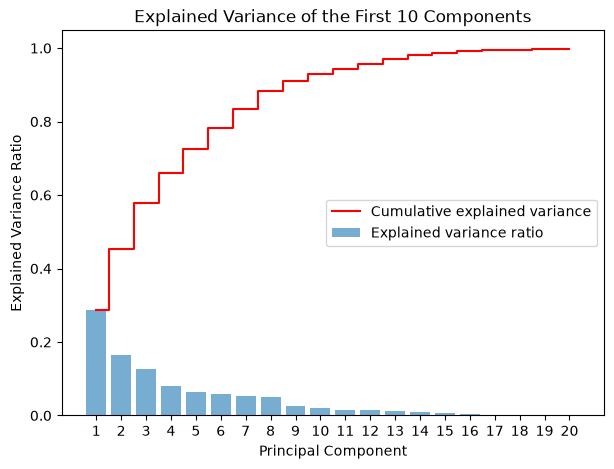

Variance explained by component 1: 28.85%
Variance explained by component 2: 45.29%
Variance explained by component 3: 57.93%
Variance explained by component 4: 66.01%
Variance explained by component 5: 72.46%
Variance explained by component 6: 78.20%
Variance explained by component 7: 83.42%
Variance explained by component 8: 88.40%
Variance explained by component 9: 90.95%
Variance explained by component 10: 92.90%
Variance explained by component 11: 94.37%
Variance explained by component 12: 95.78%
Variance explained by component 13: 97.09%
Variance explained by component 14: 98.10%
Variance explained by component 15: 98.75%
Variance explained by component 16: 99.20%
Variance explained by component 17: 99.44%
Variance explained by component 18: 99.62%
Variance explained by component 19: 99.72%
Variance explained by component 20: 99.80%


In [28]:
Input_scaled = StandardScaler().fit_transform(Input)

pca = PCA(n_components=20)
pca_fitted = pca.fit_transform(Input_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
components = np.arange(1, 21)

plt.figure(figsize=(7, 5))
plt.bar(components, explained, alpha=0.6, label='Explained variance ratio')
plt.step(components, cumulative, where='mid', color='red', label='Cumulative explained variance')
plt.xticks(components)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance of the First 10 Components')
plt.legend()
plt.show()

for i in range(20):
    print(f'Variance explained by component {i+1}: {cumulative[i]*100:.2f}%')


We can see the variance in the dataset is not dominated by any principal components. We can see that the amount of components we need to explain certain variance levels is:

80%: 7 components

90%: 9 components

95%: 12 components

99%: 16 components


In [30]:
loadings = pd.DataFrame(pca.components_.T, index=Input.columns,
                        columns=[f'PC{i+1}' for i in range(20)])
print(loadings['PC1'].sort_values(key=abs, ascending=False).head(20))

Qflow Bus 7-2      0.197721
Bus Voltage-7     -0.197227
Qflow Bus 2-7     -0.196356
Qflow Bus 3-9     -0.194922
Qflow Bus 9-3      0.194496
Bus Voltage-9     -0.194119
Bus Angles-4      -0.193953
Pflow Bus 1-4     -0.192960
Pflow Bus 4-1      0.192960
 P generation-1    0.180275
Qflow Bus 6-9      0.178434
Bus Angles-8      -0.178179
Bus Voltage-8     -0.177700
Bus Angles-9      -0.167370
Bus Angles-3      -0.162886
Bus Angles-6      -0.162764
Qflow Bus 5-7      0.162187
Bus Voltage-6     -0.161479
Qflow Bus 4-1      0.160144
Bus Voltage-5     -0.154411
Name: PC1, dtype: float64


In [4]:
#create Feature matrix
X = Input_clean.drop(columns=['Risk Factor', 'Unnamed: 0'])

#scaling
scaler = StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

In [5]:
#create target-vector
y = Input['Risk Factor']

In [6]:
#train validation test Split
Test_ratio = 0.25
Shuffle_state = 4720
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled,y,test_size=Test_ratio,random_state=Shuffle_state)
X_test, X_val, y_test, y_val = train_test_split(X_temp,y_temp,test_size=0.5,random_state=Shuffle_state)

In [7]:
#Model evaluation function
def test_mymodel(model,X,y):
    y_generated = model.predict(X)
    MSE = mean_squared_error(y, y_generated)
    R2 = r2_score(y, y_generated)
    return MSE,R2

In [9]:
lin_reg = LinearRegression().fit(X_train, y_train)
print(test_mymodel(lin_reg, X_val, y_val))

(0.01562084514713865, 0.839637037172646)


In [10]:
#target scaling for ridge and lasso
u = np.mean(y_train)
s = np.std(y_train)
y_train_s = (y_train-u)/s
y_test_s = (y_test-u)/s
y_val_s = (y_val-u)/s

In [11]:
#Ridge & Lasso Regression
Rid_reg = Ridge(alpha=1e-3).fit(X_train,y_train_s)
Las_reg = Lasso(alpha=1e-3, max_iter=5_000_000).fit(X_train,y_train_s)

In [12]:
alpha = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]
r2_ridge = []
r2_lasso = []
mse_ridge = []
mse_lasso = []

for a in alpha:
    Rid_reg = Ridge(alpha=a).fit(X_train,y_train_s)
    Las_reg = Lasso(alpha=a, max_iter=5_000_000).fit(X_train,y_train_s)

    mse_r, r2_r = test_mymodel(Rid_reg,X_val,y_val_s)
    mse_l, r2_l = test_mymodel(Las_reg,X_val,y_val_s)
    r2_ridge.append(r2_r)
    r2_lasso.append(r2_l)
    mse_ridge.append(mse_r)
    mse_lasso.append(mse_l)



In [13]:
ind_reg_max = np.argmax(r2_ridge)
ind_las_max = np.argmax(r2_lasso)

print("best R2 Ridge: ", r2_ridge[ind_reg_max])
print("best alpha Ridge: ", alpha[ind_reg_max])
print("best R2 Lasso: ", r2_lasso[ind_reg_max])
print("best alpha Lasso: ", alpha[ind_reg_max])


best R2 Ridge:  0.8380334434666874
best alpha Ridge:  0.0001
best R2 Lasso:  0.7977362108074904
best alpha Lasso:  0.0001


In [14]:

# Grid search for linear SVM

svm_C = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]

def test_parameters_linear(C_var):
    model = SVR(
        kernel="linear",
        max_iter=5_000_000,
        C=C_var
    )

    model.fit(X_train, y_train_s)

    mse, r2 = test_mymodel(model, X_val, y_val_s)

    return C_var, mse, r2, model.fit_status_


results_linear = Parallel(n_jobs=-2)(
    delayed(test_parameters_linear)(C)
    for C in svm_C
)


C_vec_linear = [r[0] for r in results_linear]
MSE_vec_linear = [r[1] for r in results_linear]
R2_vec_linear = [r[2] for r in results_linear]
status_vec_linear = [r[3] for r in results_linear]


best_idx = np.argmax(R2_vec_linear)

print("Kernel: linear")
print("Number of combinations:", np.size(R2_vec_linear))
print("Best R2:", R2_vec_linear[best_idx])
print("MSE:", MSE_vec_linear[best_idx])
print("Best C:", C_vec_linear[best_idx])
print("Converged:", status_vec_linear[best_idx] == 0)

/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=5000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=5000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Kernel: linear
Number of combinations: 8
Best R2: 0.8052734225064246
MSE: 0.19380237168989772
Best C: 100
Converged: False


/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=5000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


In [15]:
# Grid search for RBF SVM

svm_C = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_gamma = ["scale", "auto", 0.001, 0.01, 0.1, 1]

def test_parameters_rbf(C_var, gamma_var):
    model = SVR(
        kernel="rbf",
        max_iter=5_000_000,
        C=C_var,
        gamma=gamma_var
    )

    model.fit(X_train, y_train_s)

    mse, r2 = test_mymodel(model, X_val, y_val_s)

    return C_var, gamma_var, mse, r2, model.fit_status_


results_rbf = Parallel(n_jobs=-2)(
    delayed(test_parameters_rbf)(C, gamma)
    for C in svm_C
    for gamma in svm_gamma
)


C_vec_rbf = [r[0] for r in results_rbf]
gamma_vec_rbf = [r[1] for r in results_rbf]
MSE_vec_rbf = [r[2] for r in results_rbf]
R2_vec_rbf = [r[3] for r in results_rbf]
status_vec_rbf = [r[4] for r in results_rbf]


best_idx = np.argmax(R2_vec_rbf)

print("Kernel: rbf")
print("Number of combinations:", np.size(R2_vec_rbf))
print("Best R2:", R2_vec_rbf[best_idx])
print("MSE:", MSE_vec_rbf[best_idx])
print("Best C:", C_vec_rbf[best_idx])
print("Best gamma:", gamma_vec_rbf[best_idx])
print("Converged:", status_vec_rbf[best_idx] == 0)

Kernel: rbf
Number of combinations: 48
Best R2: 0.9686820366493927
MSE: 0.03116932291404981
Best C: 100
Best gamma: 0.01
Converged: True


In [16]:
# Grid search for sigmoid SVM

svm_C = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_gamma = ["scale", "auto", 0.001, 0.01, 0.1, 1]

def test_parameters_sigmoid(C_var, gamma_var):
    model = SVR(
        kernel="sigmoid",
        max_iter=5_000_000,
        C=C_var,
        gamma=gamma_var
    )

    model.fit(X_train, y_train_s)

    mse, r2 = test_mymodel(model, X_val, y_val_s)

    return C_var, gamma_var, mse, r2, model.fit_status_


results_sigmoid = Parallel(n_jobs=-2)(
    delayed(test_parameters_sigmoid)(C, gamma)
    for C in svm_C
    for gamma in svm_gamma
)


C_vec_sigmoid = [r[0] for r in results_sigmoid]
gamma_vec_sigmoid = [r[1] for r in results_sigmoid]
MSE_vec_sigmoid = [r[2] for r in results_sigmoid]
R2_vec_sigmoid = [r[3] for r in results_sigmoid]
status_vec_sigmoid = [r[4] for r in results_sigmoid]


best_idx = np.argmax(R2_vec_sigmoid)

print("Kernel: sigmoid")
print("Number of combinations:", np.size(R2_vec_sigmoid))
print("Best R2:", R2_vec_sigmoid[best_idx])
print("MSE:", MSE_vec_sigmoid[best_idx])
print("Best C:", C_vec_sigmoid[best_idx])
print("Best gamma:", gamma_vec_sigmoid[best_idx])
print("Converged:", status_vec_sigmoid[best_idx] == 0)

Kernel: sigmoid
Number of combinations: 48
Best R2: 0.6439106848539204
MSE: 0.35439925405672223
Best C: 1
Best gamma: 0.001
Converged: True


In [17]:
# Grid search for polynomial SVM

svm_C = [0.1, 1, 10]#[0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_gamma =  [0.1, 1, 10]#["scale", "auto"] 
svm_deg = [2, 3]

def test_parameters_poly(C_var, gamma_var, deg):
    model = SVR(
        kernel="poly",
        max_iter=1_000_000,
        C=C_var,
        gamma=gamma_var,
        degree=deg
    )

    model.fit(X_train, y_train_s)

    mse, r2 = test_mymodel(model, X_val, y_val_s)

    return C_var, gamma_var, deg, mse, r2, model.fit_status_


results_poly = Parallel(n_jobs=-2)(
    delayed(test_parameters_poly)(C, gamma, deg)
    for C in svm_C
    for gamma in svm_gamma
    for deg in svm_deg
)


C_vec_poly = [r[0] for r in results_poly]
gamma_vec_poly = [r[1] for r in results_poly]
deg_vec_poly = [r[2] for r in results_poly]
MSE_vec_poly = [r[3] for r in results_poly]
R2_vec_poly = [r[4] for r in results_poly]
status_vec_poly = [r[5] for r in results_poly]


print("Kernel: poly")
print("Number of combinations:", np.size(R2_vec_poly))

for deg in np.unique(deg_vec_poly):

    # Indices belonging to this degree
    indices = [i for i, d in enumerate(deg_vec_poly) if d == deg]

    # Best index for this degree
    best_idx = max(indices, key=lambda i: R2_vec_poly[i])

    print(f"\nDegree: {deg}")
    print("Best R2:", R2_vec_poly[best_idx])
    print("MSE:", MSE_vec_poly[best_idx])
    print("Best C:", C_vec_poly[best_idx])
    print("Best gamma:", gamma_vec_poly[best_idx])
    print("Converged:", status_vec_poly[best_idx] == 0)

print("Non-converged combinations:")

for i in range(len(status_vec_poly)):
    if status_vec_poly[i] != 0:
        print(
            "Degree:", deg_vec_poly[i],
            "| C:", C_vec_poly[i],
            "| gamma:", gamma_vec_poly[i]
        )

/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=1000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=1000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=1000000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=1000000).  Consider pre-processing your data with StandardScaler or

Kernel: poly
Number of combinations: 18

Degree: 2
Best R2: 0.9390280194257087
MSE: 0.060682597075470544
Best C: 0.1
Best gamma: 1
Converged: False

Degree: 3
Best R2: 0.930521442405704
MSE: 0.06914880041894632
Best C: 0.1
Best gamma: 0.1
Converged: False
Non-converged combinations:
Degree: 3 | C: 0.1 | gamma: 0.1
Degree: 2 | C: 0.1 | gamma: 1
Degree: 3 | C: 0.1 | gamma: 1
Degree: 2 | C: 0.1 | gamma: 10
Degree: 3 | C: 0.1 | gamma: 10
Degree: 2 | C: 1 | gamma: 0.1
Degree: 3 | C: 1 | gamma: 0.1
Degree: 2 | C: 1 | gamma: 1
Degree: 3 | C: 1 | gamma: 1
Degree: 2 | C: 1 | gamma: 10
Degree: 3 | C: 1 | gamma: 10
Degree: 2 | C: 10 | gamma: 0.1
Degree: 3 | C: 10 | gamma: 0.1
Degree: 2 | C: 10 | gamma: 1
Degree: 3 | C: 10 | gamma: 1
Degree: 2 | C: 10 | gamma: 10
Degree: 3 | C: 10 | gamma: 10


In [18]:
#Deep neural network


mlp = MLPRegressor(hidden_layer_sizes=(200,200,200,200,200), activation='relu', solver='adam', alpha=0.0001, max_iter=200, shuffle=True, random_state=42)
mlp.fit(X_train,y_train_s)
print(test_mymodel(mlp,X_val,y_val_s))

(0.0177590869254119, 0.982156223444315)
